Loading data and grouping by lesion_id...
train 6959 | val 1529 | test 1527 (no shared lesions)
Found 6959 validated image filenames belonging to 7 classes.
Found 1529 validated image filenames belonging to 7 classes.

TRAINING MODEL A: RESNET-50
Epoch 1/20
218/218 ━━━━━━━━━━━━━━━━━━━━ 232s 1s/step - accuracy: 0.5350 - loss: 0.2742 - val_accuracy: 0.6422 - val_loss: 0.1698 - learning_rate: 1.0000e-04
Epoch 2/20
218/218 ━━━━━━━━━━━━━━━━━━━━ 235s 1s/step - accuracy: 0.6908 - loss: 0.1502 - val_accuracy: 0.6619 - val_loss: 0.1478 - learning_rate: 1.0000e-04
Epoch 3/20
218/218 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.7278 - loss: 0.1173 - val_accuracy: 0.7057 - val_loss: 0.1215 - learning_rate: 1.0000e-04
Epoch 4/20
218/218 ━━━━━━━━━━━━━━━━━━━━ 282s 1s/step - accuracy: 0.7600 - loss: 0.0993 - val_accuracy: 0.7332 - val_loss: 0.1272 - learning_rate: 1.0000e-04
Epoch 5/20
218/218 ━━━━━━━━━━━━━━━━━━━━ 276s 1s/step - accuracy: 0.7786 - loss: 0.0878 - val_accuracy: 0.7521 - val_loss: 0.1

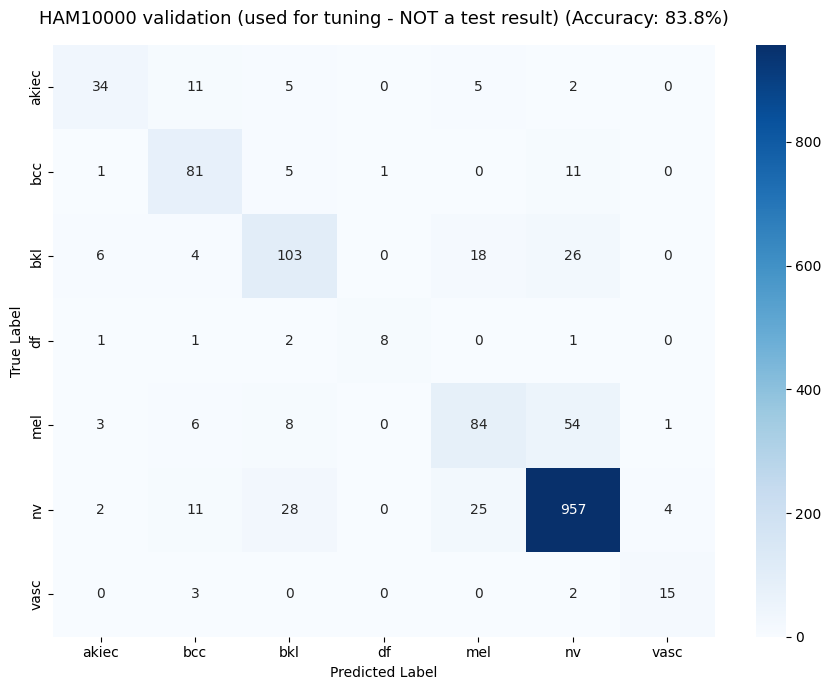

In [1]:
# ===================== CELL 1: TRAIN (HAM10000) + TUNE ON VALIDATION =====================
# Final pipeline from "Entire Process.ipynb": ResNet-50 + EfficientNetB2 -> tuned blend weight
# -> per-class multipliers (Nelder-Mead) -> ResNet "second opinion" nv->mel tie-breaker.
# Run from inside "CV Lab Project/".   pip install tensorflow pandas numpy scipy scikit-learn matplotlib seaborn
#
# Leakage controls: HAM10000 split by lesion_id into train / val / test (GroupShuffleSplit).
#   * train  -> fitting the two networks
#   * val    -> early stopping AND tuning of blend weight, class multipliers, tie-breaker threshold
#   * test   -> never touched until cell 3;  ISIC2019 (cell 2) has HAM10000 images removed by image_id.
# All tuned values are frozen after this cell and applied unchanged to every later test set.
import os
from pathlib import Path
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.applications import ResNet50, EfficientNetB2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout, BatchNormalization, Lambda
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns

tf.keras.utils.set_random_seed(42)
BASE = Path.cwd()
HAM_CSV, HAM_IMGS, ISIC_DIR = BASE / "data" / "HAM10000_metadata.csv", BASE / "data" / "images", BASE / "data" / "ISIC2019_Dataset"
MODEL_DIR = BASE / "models"; OUT_DIR = BASE / "research_results"; MODEL_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)
class_labels = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]      # same alphabetical order Keras uses
NV_IDX, MEL_IDX = class_labels.index("nv"), class_labels.index("mel")
img_size, batch_size = (260, 260), 32

# ==========================================================
# 1. DATA SPLIT (STRICT GROUPING BY lesion_id): train / val / test
# ==========================================================
print("Loading data and grouping by lesion_id...")
df = pd.read_csv(HAM_CSV)
paths = {p.stem: str(p) for p in HAM_IMGS.rglob("*.jpg")}
df = df[df["image_id"].isin(paths)].copy(); df["path"] = df["image_id"].map(paths)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trval_idx, test_idx = next(gss1.split(df, groups=df["lesion_id"]))
trval_df, test_df = df.iloc[trval_idx].copy(), df.iloc[test_idx].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=42)
tr_idx, va_idx = next(gss2.split(trval_df, groups=trval_df["lesion_id"]))
train_df, val_df = trval_df.iloc[tr_idx].copy(), trval_df.iloc[va_idx].copy()
assert not (set(train_df.lesion_id) & set(val_df.lesion_id)) and not (set(train_df.lesion_id) & set(test_df.lesion_id)) \
   and not (set(val_df.lesion_id) & set(test_df.lesion_id)), "lesion leakage!"
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)} (no shared lesions)")

# ==========================================================
# 2. GENERATORS (RAW 0-255 PIXELS AT 260x260; models scale internally)
# ==========================================================
train_datagen = ImageDataGenerator(rotation_range=90, horizontal_flip=True, vertical_flip=True, zoom_range=0.2)
eval_datagen = ImageDataGenerator()

def make_gen(frame, gen, shuffle):
    return gen.flow_from_dataframe(dataframe=frame, x_col="path", y_col="dx", classes=class_labels,
                                   target_size=img_size, batch_size=batch_size, class_mode="categorical", shuffle=shuffle)

train_gen = make_gen(train_df, train_datagen, True)
val_gen = make_gen(val_df, eval_datagen, False)

numeric_labels = train_gen.classes
raw_weights = compute_class_weight("balanced", classes=np.unique(numeric_labels), y=numeric_labels)
class_weights_dict = dict(enumerate(np.sqrt(raw_weights)))             # sqrt-smoothed, train only

def focal_loss(gamma=1.5, alpha=0.25):
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
        cross_entropy = -y_true * tf.math.log(y_pred)
        return tf.reduce_sum(alpha * tf.math.pow(1.0 - y_pred, gamma) * cross_entropy, axis=-1)
    return loss_fn

# ==========================================================
# 3. MODEL A: RESNET-50
# ==========================================================
print("\n" + "=" * 60 + "\nTRAINING MODEL A: RESNET-50\n" + "=" * 60)
raw_input_a = Input(shape=(260, 260, 3))
prep_a = Lambda(resnet_preprocess)(raw_input_a)
base_resnet = ResNet50(weights="imagenet", include_top=False, input_tensor=prep_a)
for layer in base_resnet.layers:
    layer.trainable = True if "conv5" in layer.name else False          # fine-tune conv5 block
x_a = GlobalAveragePooling2D()(base_resnet.output)
x_a = BatchNormalization()(x_a); x_a = Dropout(0.4)(x_a)
x_a = Dense(256, activation="relu")(x_a); x_a = Dropout(0.3)(x_a)
model_resnet = Model(inputs=raw_input_a, outputs=Dense(7, activation="softmax")(x_a))
model_resnet.compile(optimizer=Adam(learning_rate=0.0001), loss=focal_loss(gamma=1.5), metrics=["accuracy"])
model_resnet.fit(train_gen, validation_data=val_gen, epochs=20, class_weight=class_weights_dict,
                 callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)])
model_resnet.save(MODEL_DIR / "final_resnet50.keras")

# ==========================================================
# 4. MODEL B: EFFICIENTNET-B2
# ==========================================================
print("\n" + "=" * 60 + "\nTRAINING MODEL B: EFFICIENTNET-B2\n" + "=" * 60)
raw_input_b = Input(shape=(260, 260, 3))
base_effnet = EfficientNetB2(weights="imagenet", include_top=False, input_tensor=raw_input_b)
base_effnet.trainable = True
for layer in base_effnet.layers[:-40]:
    layer.trainable = False                                             # unfreeze top 40
x_b = GlobalAveragePooling2D()(base_effnet.output)
x_b = BatchNormalization()(x_b); x_b = Dropout(0.4)(x_b)
x_b = Dense(256, activation="relu")(x_b); x_b = Dropout(0.3)(x_b)
model_effnet = Model(inputs=raw_input_b, outputs=Dense(7, activation="softmax")(x_b))
model_effnet.compile(optimizer=Adam(learning_rate=0.0001), loss=focal_loss(gamma=1.2), metrics=["accuracy"])
model_effnet.fit(train_gen, validation_data=val_gen, epochs=20, class_weight=class_weights_dict,
                 callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)])
model_effnet.save(MODEL_DIR / "final_effnetb2.keras")

# ==========================================================
# 5. HELPERS (reused in cells 2 and 3)
# ==========================================================
def predict_df(frame):
    g = make_gen(frame, eval_datagen, False)
    return g.classes, model_resnet.predict(g, verbose=0), model_effnet.predict(g, verbose=0)

def final_predict(preds_resnet, preds_effnet):
    """Frozen final pipeline: blend -> class multipliers -> ResNet nv->mel second opinion."""
    blended = TUNED["w"] * preds_resnet + (1.0 - TUNED["w"]) * preds_effnet
    pred = np.argmax(blended * TUNED["mult"], axis=1)
    if TUNED["thresh"] < 1.0:
        pred[(pred == NV_IDX) & (preds_resnet[:, MEL_IDX] > TUNED["thresh"])] = MEL_IDX
    return pred

def report(title, y_true, preds_resnet, preds_effnet):
    pred = final_predict(preds_resnet, preds_effnet)
    plain = np.argmax(0.5 * preds_resnet + 0.5 * preds_effnet, axis=1)   # reference only: untuned 50/50 average
    print("\n" + "=" * 70 + f"\n{title}  (n={len(y_true)})\n" + "=" * 70)
    print(f"ResNet-50 alone:       acc {accuracy_score(y_true, preds_resnet.argmax(1))*100:.2f}%")
    print(f"EfficientNetB2 alone:  acc {accuracy_score(y_true, preds_effnet.argmax(1))*100:.2f}%")
    print(f"Plain 50/50 average:   acc {accuracy_score(y_true, plain)*100:.2f}% | balanced {balanced_accuracy_score(y_true, plain)*100:.2f}%")
    print(f"FINAL tuned pipeline:  acc {accuracy_score(y_true, pred)*100:.2f}% | balanced {balanced_accuracy_score(y_true, pred)*100:.2f}%")
    print(classification_report(y_true, pred, labels=range(7), target_names=class_labels, zero_division=0))
    plt.figure(figsize=(9, 7))
    sns.heatmap(confusion_matrix(y_true, pred, labels=range(7)), annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f"{title} (Accuracy: {accuracy_score(y_true, pred)*100:.1f}%)", fontsize=13, pad=15)
    plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.tight_layout()
    plt.savefig(OUT_DIR / ("final_" + "".join(ch if ch.isalnum() else "_" for ch in title) + "_cm.png"), dpi=150); plt.show()

# ==========================================================
# 6. TUNE EVERYTHING ON THE VALIDATION SET ONLY, THEN FREEZE
# ==========================================================
y_val, pr_val, pe_val = predict_df(val_df)
print(f"\nValidation: ResNet-50 {accuracy_score(y_val, pr_val.argmax(1))*100:.2f}% | EfficientNetB2 {accuracy_score(y_val, pe_val.argmax(1))*100:.2f}%")

# 6a. grid search for ensemble blend weight
best_weight, best_acc = 0.5, 0.0
for w in np.linspace(0.0, 1.0, 21):
    a = accuracy_score(y_val, np.argmax(w * pr_val + (1.0 - w) * pe_val, axis=1))
    if a > best_acc: best_acc, best_weight = a, w
print(f"Optimal blend: {best_weight*100:.0f}% ResNet-50 + {(1-best_weight)*100:.0f}% EfficientNetB2 (val acc {best_acc*100:.2f}%)")
blended_val = best_weight * pr_val + (1.0 - best_weight) * pe_val

# 6b. per-class decision multipliers (Nelder-Mead)
res_7 = minimize(lambda m: -accuracy_score(y_val, np.argmax(blended_val * m, axis=1)), np.ones(7),
                 method="Nelder-Mead", bounds=[(0.2, 3.5)] * 7, options={"maxiter": 500})
best_mult = res_7.x
pred_cal_val = np.argmax(blended_val * best_mult, axis=1)
print("Class multipliers:", dict(zip(class_labels, best_mult.round(3))), f"-> val acc {accuracy_score(y_val, pred_cal_val)*100:.2f}%")

# 6c. ResNet second-opinion tie-breaker threshold (nv -> mel)
best_final_acc, best_thresh = accuracy_score(y_val, pred_cal_val), 1.0          # 1.0 = no change
for thresh in np.linspace(0.40, 0.95, 56):
    t = pred_cal_val.copy(); t[(pred_cal_val == NV_IDX) & (pr_val[:, MEL_IDX] > thresh)] = MEL_IDX
    a = accuracy_score(y_val, t)
    if a > best_final_acc: best_final_acc, best_thresh = a, thresh
print(f"Tie-breaker threshold: {best_thresh:.3f} (1.0 = not used) -> val acc {best_final_acc*100:.2f}%")

TUNED = {"w": best_weight, "mult": best_mult, "thresh": best_thresh}
report("HAM10000 validation (used for tuning - NOT a test result)", y_val, pr_val, pe_val)


ISIC2019: 24703 -> 14885 after removing 9818 HAM10000 duplicates
dx
nv       6170
mel      3409
bcc      2809
bkl      1525
akiec     737
df        124
vasc      111
Name: count, dtype: int64
Found 14885 validated image filenames belonging to 7 classes.

ISIC2019 external test (HAM-trained)  (n=14885)
ResNet-50 alone:       acc 49.67%
EfficientNetB2 alone:  acc 44.57%
Plain 50/50 average:   acc 50.11% | balanced 38.69%
FINAL tuned pipeline:  acc 52.57% | balanced 34.71%
              precision    recall  f1-score   support

       akiec       0.24      0.07      0.11       737
         bcc       0.65      0.32      0.43      2809
         bkl       0.20      0.45      0.28      1525
          df       0.15      0.17      0.16       124
         mel       0.72      0.20      0.32      3409
          nv       0.63      0.88      0.73      6170
        vasc       0.41      0.33      0.37       111

    accuracy                           0.53     14885
   macro avg       0.43      0.35    

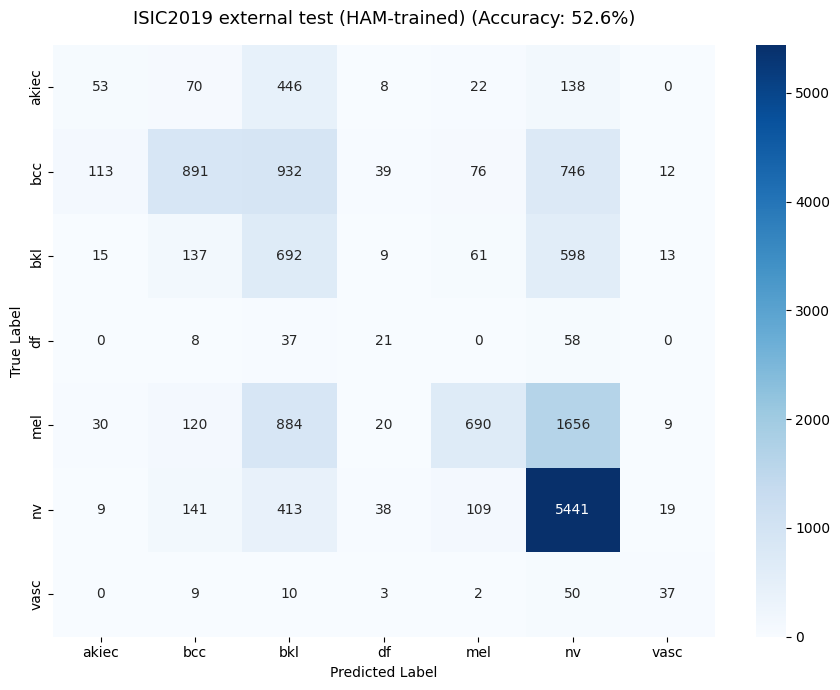

In [2]:
# ===================== CELL 2: TEST ON ISIC2019 (external; HAM10000 duplicates removed) =====================
# Models and tuned values (blend weight, class multipliers, tie-breaker) are frozen from cell 1.
ISIC_FOLDER_TO_DX = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df", "MEL": "mel", "NV": "nv", "VASC": "vasc"}  # SCC dropped
def build_isic_deduped():
    rows = [(p.stem, str(p), dx) for f, dx in ISIC_FOLDER_TO_DX.items() for p in (ISIC_DIR / f).rglob("*.jpg")]
    d = pd.DataFrame(rows, columns=["image_id", "path", "dx"]); n0 = len(d)
    d = d[~d["image_id"].isin(set(df["image_id"]))].reset_index(drop=True)
    print(f"ISIC2019: {n0} -> {len(d)} after removing {n0 - len(d)} HAM10000 duplicates"); return d

isic_df = build_isic_deduped(); print(isic_df["dx"].value_counts())
y_isic, pr_isic, pe_isic = predict_df(isic_df)
report("ISIC2019 external test (HAM-trained)", y_isic, pr_isic, pe_isic)


Found 1527 validated image filenames belonging to 7 classes.

HAM10000 held-out test (in-dataset)  (n=1527)
ResNet-50 alone:       acc 78.26%
EfficientNetB2 alone:  acc 74.53%
Plain 50/50 average:   acc 79.70% | balanced 72.46%
FINAL tuned pipeline:  acc 81.99% | balanced 70.55%
              precision    recall  f1-score   support

       akiec       0.60      0.38      0.46        48
         bcc       0.60      0.79      0.68        66
         bkl       0.68      0.65      0.66       172
          df       0.53      0.80      0.64        10
         mel       0.58      0.51      0.54       186
          nv       0.91      0.93      0.92      1016
        vasc       0.90      0.90      0.90        29

    accuracy                           0.82      1527
   macro avg       0.68      0.71      0.69      1527
weighted avg       0.82      0.82      0.82      1527



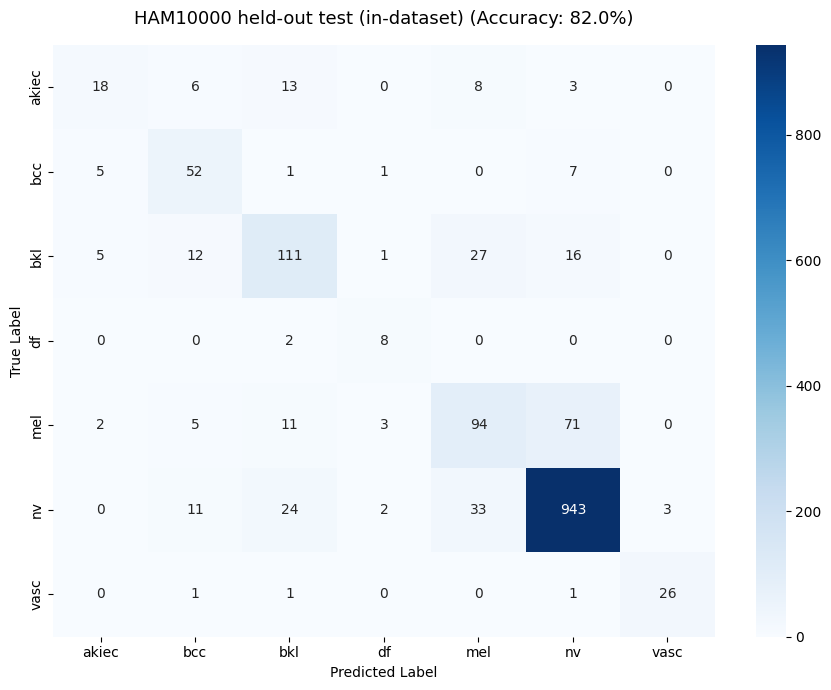


Combined HAM-test + ISIC2019  (n=16412)
ResNet-50 alone:       acc 52.33%
EfficientNetB2 alone:  acc 47.36%
Plain 50/50 average:   acc 52.86% | balanced 41.62%
FINAL tuned pipeline:  acc 55.31% | balanced 38.06%
              precision    recall  f1-score   support

       akiec       0.28      0.09      0.14       785
         bcc       0.64      0.33      0.43      2875
         bkl       0.22      0.47      0.30      1697
          df       0.19      0.22      0.20       134
         mel       0.70      0.22      0.33      3595
          nv       0.66      0.89      0.75      7186
        vasc       0.53      0.45      0.49       140

    accuracy                           0.55     16412
   macro avg       0.46      0.38      0.38     16412
weighted avg       0.60      0.55      0.52     16412



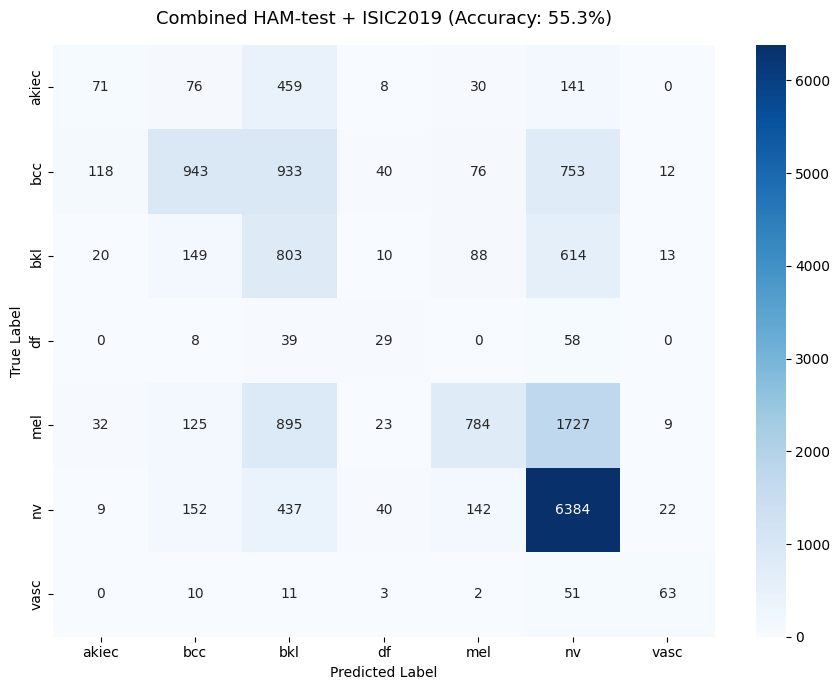

In [3]:
# ===================== CELL 3: TEST ON COMBINED (HAM10000 held-out test + ISIC2019) =====================
if "y_isic" not in globals():
    isic_df = build_isic_deduped(); y_isic, pr_isic, pe_isic = predict_df(isic_df)
y_ham, pr_ham, pe_ham = predict_df(test_df)
report("HAM10000 held-out test (in-dataset)", y_ham, pr_ham, pe_ham)
report("Combined HAM-test + ISIC2019", np.concatenate([y_ham, y_isic]),
       np.concatenate([pr_ham, pr_isic]), np.concatenate([pe_ham, pe_isic]))
